# Planta Física: Etapa de Investigación
### Formulación, datos y supuestos
- Integrantes:

José Manuel Muñoz Barranco - A01662395 

Mateo Vasconselos Salazar - A01782297

Daniela Grajales Anguiano - A01661228

In [1]:
#Librerías
from pathlib import Path
from IPython.display import Image, display
import math

## 1. Funciones a utilizar en el notebook:
Funciones sencillas de carga de datos para poder visualizar los cálculos a mano y comprobarlos

In [2]:
def buscar_imagen_calculo(nombre_imagen: str):
    directorio_actual = Path.cwd()
    ruta_imagen = directorio_actual / "calculos" / nombre_imagen
    if not ruta_imagen.name.endswith(".png"):
        ruta_imagen = ruta_imagen.with_suffix(".png")

    if ruta_imagen.is_file():
        print(f"Imagen encontrada en {ruta_imagen}")
        return ruta_imagen
    else: 
        print("no se encontro la imagen, revisar si se adjunto correctamente")
        return None

## 2. Formulación y supuestos:
- Objetivo: El objetivo de este modelo es minimizar el consumo de agua potable (P) que requieren los cuatro edificios del campus (Aulas 1, Biblioteca, Cedetec y Aulas 2) durante un mes, asignando la cantidad de agua tratada (T) a cada uno de los cuatro edificios de manera eficiente siguiendo la capacidad y dominios.
- Edificios: Como se menciono previamente el modelo solo esta enfocado en los siguientes edificios: Aulas 1, Biblioteca, Cedetec y Aulas 2.
- Genes: Cada solución candidata se representa como un cromosoma de 4 genes enteros: k = ($k_1$, $k_2$, $k_3$, $k_4$). Cada gen $k_i$ es la decisión de qué fracción $x_i = k_i/10$ de la demanda mensual del edificio $i$ se abastece con agua tratada; el resto $(1-x_i)$ se abastece con agua potable. El orden de los genes es el de la tabla de datos: Aulas 1, Biblioteca, Cedetec, Aulas 2.
- Dominios: 

**$k_1 \in \{0, 1, 2, 3, 4, 5, 6, 7, 8\}$ (Aulas 1):** Determina la fracción $x_1 \in [0.0, 0.8]$ de agua tratada (surtido del 0% al 80%).

**$k_2 \in \{0, 1, 2, 3, 4, 5, 6, 7, 8\}$ (Biblioteca):** Determina la fracción $x_2 \in [0.0, 0.8]$ de agua tratada (surtido del 0% al 80%).

**$k_3 \in \{0, 1, 2, 3, 4, 5, 6\}$ (Cedetec):** Determina la fracción $x_3 \in [0.0, 0.6]$ de agua tratada (surtido del 0% al 60%).

**$k_4 \in \{0, 1, 2, 3, 4, 5, 6, 7, 8\}$ (Aulas 2):** Determina la fracción $x_4 \in [0.0, 0.8]$ de agua tratada (surtido del 0% al 80%).
### Datos y supuestos

- Datos observados: 
Las demandas son consumos agregados de marzo de 2025 del Campus Ciudad de México (Planta Física), tomados de los cuatro registros de marzo de 2025 de `consumo_agua_2023_2026.csv`, sin banderas de imputación, cero ni anomalía.

| Edificio | Demanda $D_i$ (m³/mes) | Gen $k_i$ | Fracción $x_i$ |
|---|---|---|---|
| Aulas 1 | 847.00 | 0, …, 8 | $k_1/10$ |
| Biblioteca | 462.00 | 0, …, 8 | $k_2/10$ |
| Cedetec | 284.21 | 0, …, 6 | $k_3/10$ |
| Aulas 2 | 683.00 | 0, …, 8 | $k_4/10$ |
| **Total** | **2276.21** | | |

- Supuestos didácticos (no son datos observados):
- La capacidad de la planta $C = 1410\ \text{m}^3$ viene de `parametros_reto.csv` y fue calibrada por el docente; es un supuesto didáctico.
- Los topes por edificio (80 % en Aulas 1, Biblioteca y Aulas 2; 60 % en Cedetec) también son didácticos.
- El modelo describe un caso académico de un mes. No acredita una solución hidráulica ni sanitaria validada.

- Restricción: 
Se minimiza $P$ sujeto a los dominios de $k_i$ y a $T \le C$. Una codificación fuera de dominio se rechaza; no se redondea ni se corrige.
- Supuestos: Capacidad de la planta C = 1410m^3
- Ecuaciones del modelo matemático: 

**Volumen total de agua tratada demandada ($T$):**
   $$T = \sum_{i=1}^{4} D_i \cdot x_i = \sum_{i=1}^{4} D_i \frac{k_i}{10} \quad [\text{m}^3]$$


**Volumen total de agua potable requerida ($P$):**
   $$P = 2276.21 - T \quad [\text{m}^3]$$


**Exceso sobre la capacidad ($E$):**
   $$E = \max(0, T - C) \quad [\text{m}^3]$$


**Función de Aptitud / Fitness Escalar ($F(k)$):**
   Se evalúa la aptitud del candidato (donde un valor **menor es mejor**) considerando una tolerancia numérica de $10^{-8} \text{ m}^3$:
   $$F(k) = \begin{cases} \dfrac{P}{2276.21}, & \text{si } T \le C \quad (\text{Factible}) \\ 1 + \dfrac{E}{C}, & \text{si } T > C \quad (\text{Infactible}) \end{cases}$$


## 3. Calculos a mano:

Imagen encontrada en /home/jose-manuel/sandbox/Equipo_5_PlantaFisica/calculos/6,6,6,6.png


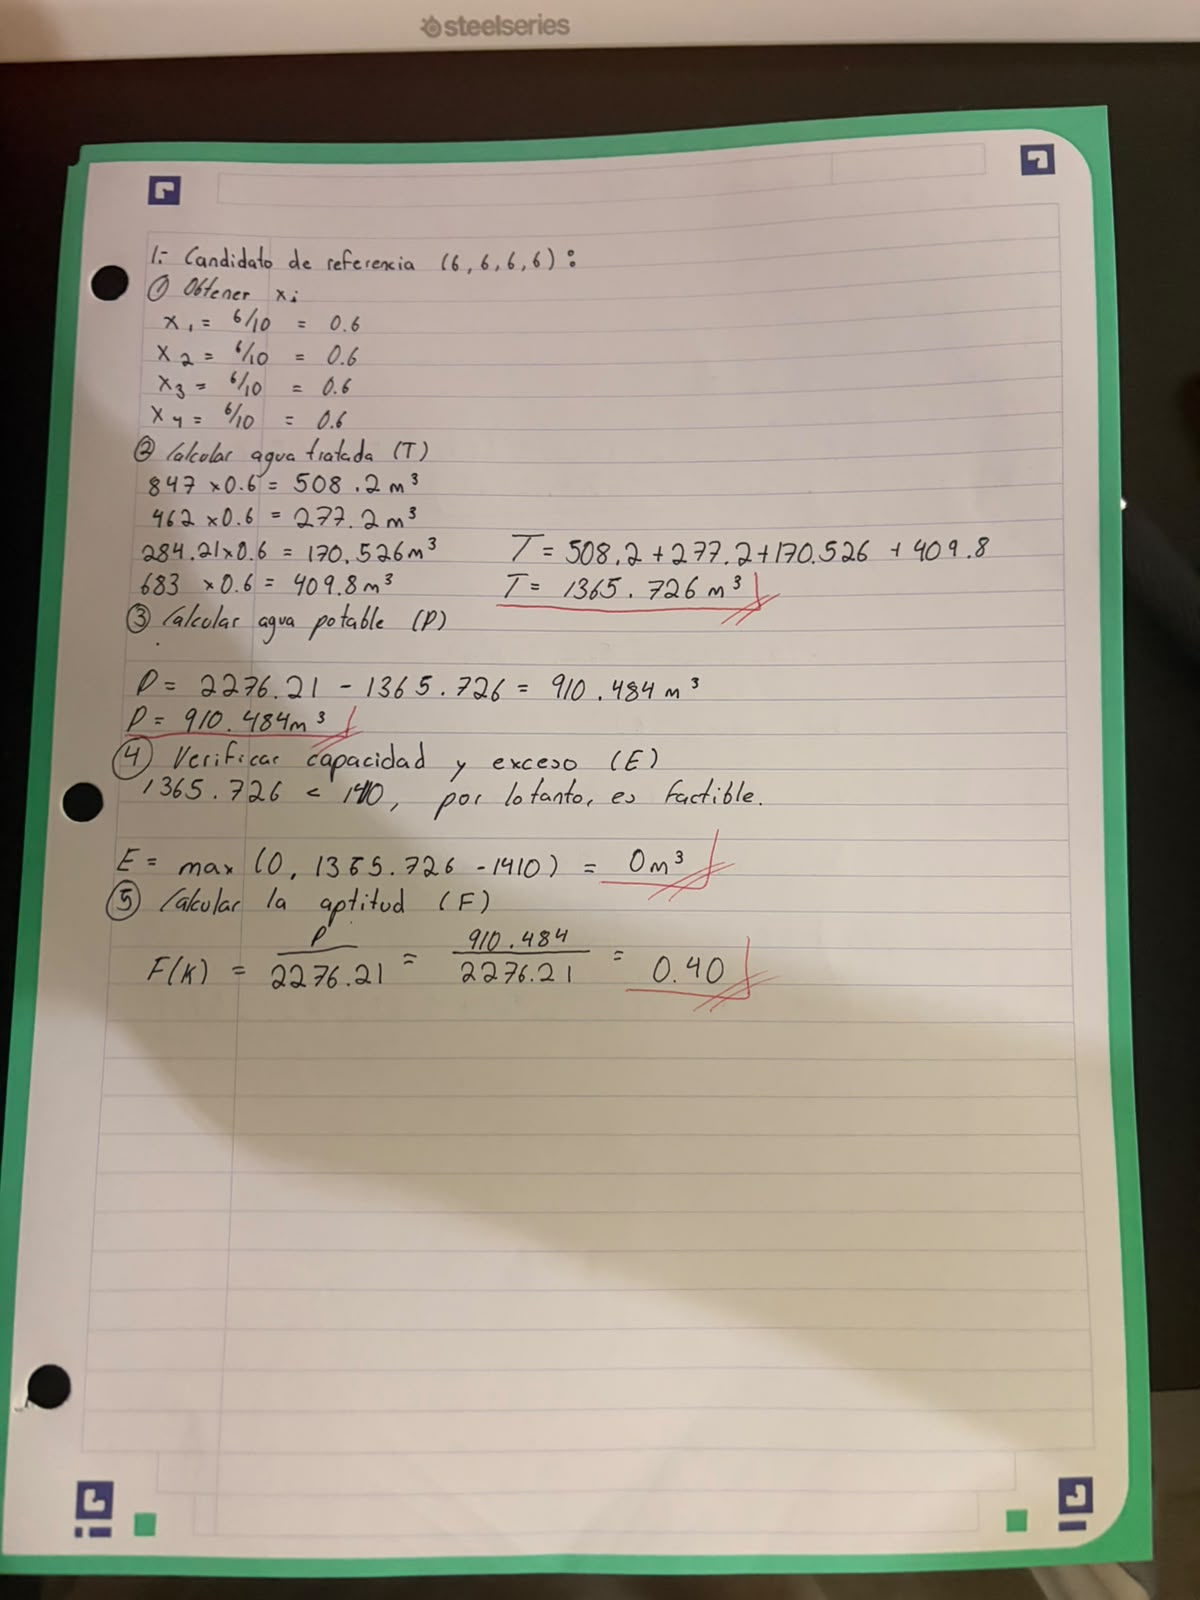

In [3]:
ruta_img = buscar_imagen_calculo("6,6,6,6.png")

if ruta_img:
    display(Image(filename=ruta_img))

Imagen encontrada en /home/jose-manuel/sandbox/Equipo_5_PlantaFisica/calculos/8,8,6,8.png


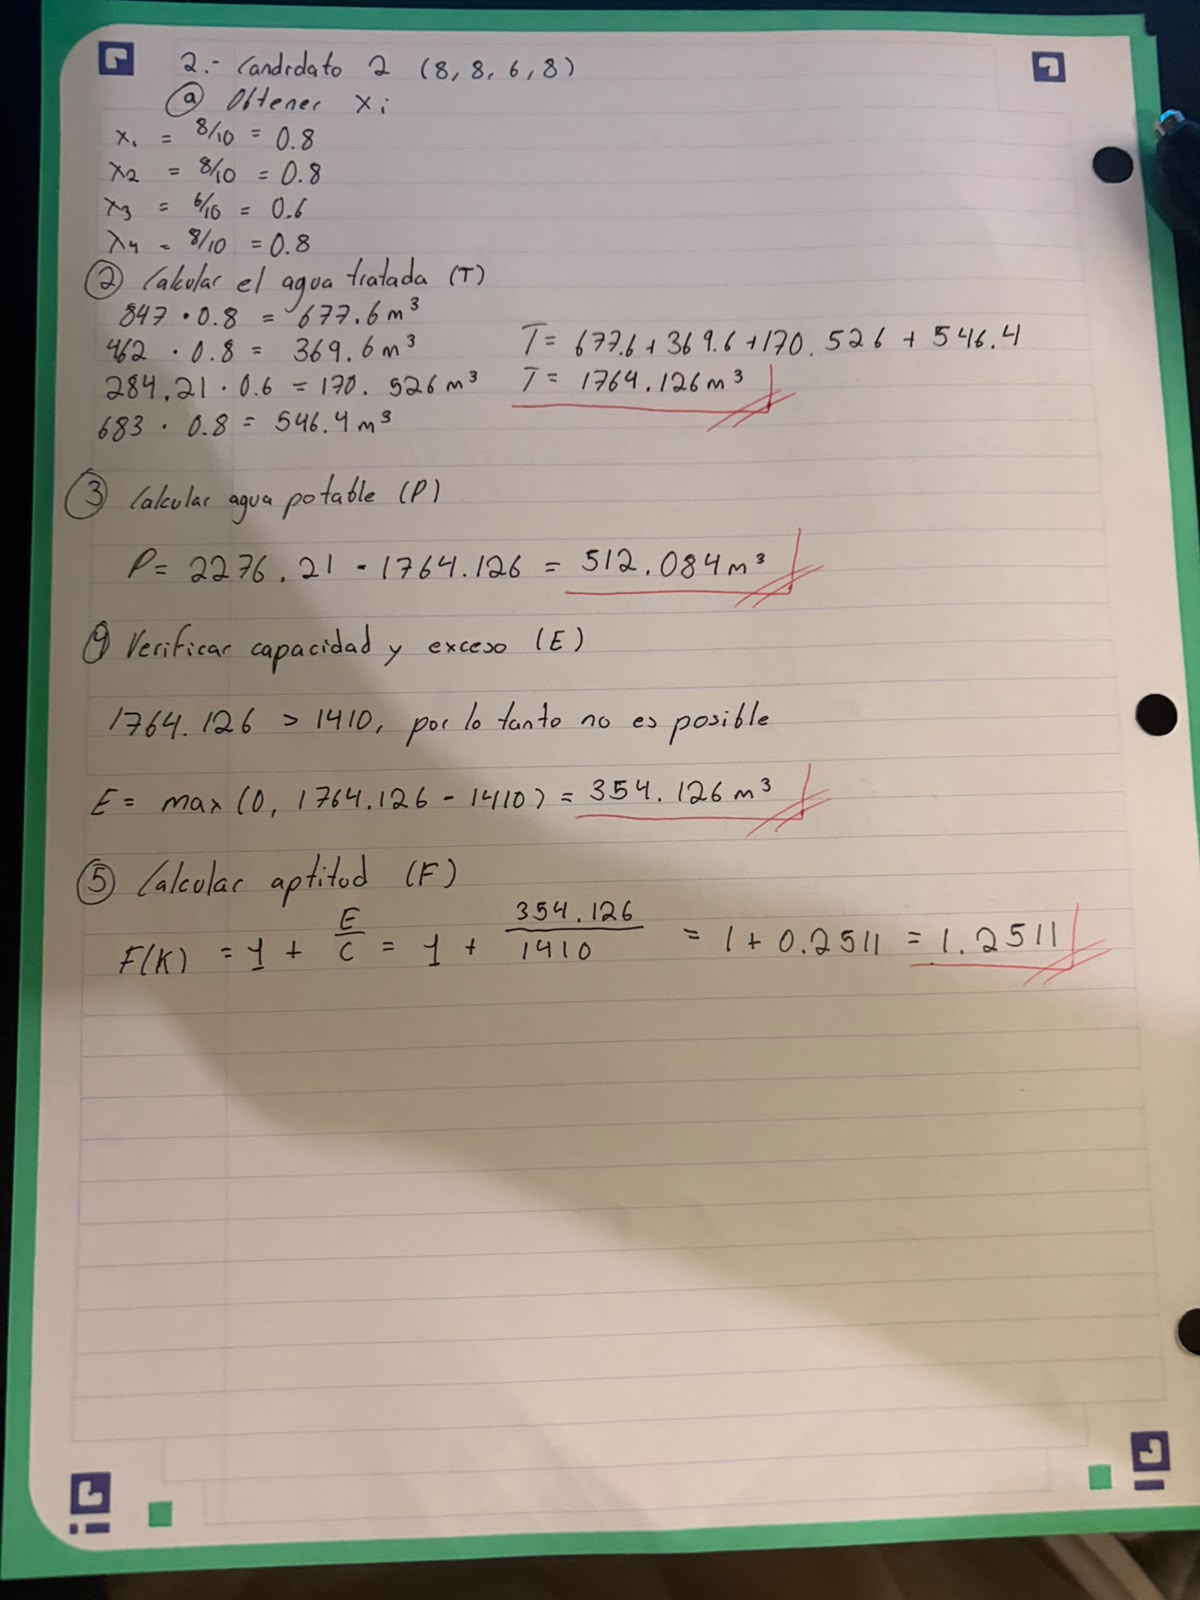

In [4]:
ruta_img = buscar_imagen_calculo("8,8,6,8.png")

if ruta_img:
    display(Image(filename=ruta_img))

## 4. Calculos comprobados:

In [ ]:
NOMBRES = ["Aulas 1", "Biblioteca", "Cedetec", "Aulas 2"]
DEMANDAS = [847.0, 462.0, 284.21, 683.0]      
TOPES_K = [8, 8, 6, 8]                        
CAPACIDAD = 1410.0                            
TOL = 1e-8                                    
DEMANDA_TOTAL = sum(DEMANDAS)             


def validar_codificacion(k):
    """Rechaza una codificación inválida; no la redondea ni la corrige."""
    if len(k) != 4:
        raise ValueError(f"Se requieren 4 genes y se recibieron {len(k)}: {k}")
    for nombre, ki, tope in zip(NOMBRES, k, TOPES_K):
        if isinstance(ki, bool) or not isinstance(ki, int):
            raise ValueError(f"Gen de {nombre} no es entero: {ki!r}")
        if not 0 <= ki <= tope:
            raise ValueError(f"Gen de {nombre} fuera de dominio 0..{tope}: {ki}")


def evaluar_candidato(k, verbose=True):
    """Devuelve T, P, E, F y factibilidad. Menor F es mejor."""
    validar_codificacion(k)
    x = [ki / 10 for ki in k]
    T = sum(xi * di for xi, di in zip(x, DEMANDAS))   
    P = DEMANDA_TOTAL - T                             
    E = max(0.0, T - CAPACIDAD)                       
    factible = T <= CAPACIDAD + TOL
    F = P / DEMANDA_TOTAL if factible else 1 + E / CAPACIDAD

    res = {"k": tuple(k), "T": T, "P": P, "E": E, "F": F, "factible": factible}
    if verbose:
        print(f"Candidato: {list(k)}")
        print(f"Agua tratada (T): {T:.3f} m3")
        print(f"Agua potable (P): {P:.3f} m3")
        print(f"Exceso (E):       {E:.3f} m3")
        print(f"Factible:         {'sí' if factible else 'no'}")
        print(f"Aptitud (F):      {F:.5f}")
        print("=" * 30)
    return res


r1 = evaluar_candidato([6, 6, 6, 6])
r2 = evaluar_candidato([8, 8, 6, 8])

assert math.isclose(r1["T"], 1365.726, abs_tol=1e-3)
assert math.isclose(r1["P"], 910.484, abs_tol=1e-3)
assert math.isclose(r1["F"], 0.4, abs_tol=1e-4)
assert r1["factible"]
assert math.isclose(r2["T"], 1764.126, abs_tol=1e-3)
assert math.isclose(r2["P"], 512.084, abs_tol=1e-3)
assert math.isclose(r2["E"], 354.126, abs_tol=1e-3)
assert math.isclose(r2["F"], 1.25115, abs_tol=1e-4)
assert not r2["factible"]
print("El evaluador coincide con los cálculos a mano.")

evaluar_candidato([6,6,6,6])
evaluar_candidato([8,8,6,8])

Candidato: [6, 6, 6, 6]
Agua tratada (T): 1365.726 m3
Agua potable (P): 910.484 m3
Exceso (E):       0.000 m3
Factible:         sí
Aptitud (F):      0.40000
Candidato: [8, 8, 6, 8]
Agua tratada (T): 1764.126 m3
Agua potable (P): 512.084 m3
Exceso (E):       354.126 m3
Factible:         no
Aptitud (F):      1.25115
El evaluador coincide con los cálculos a mano.
Candidato: [6, 6, 6, 6]
Agua tratada (T): 1365.726 m3
Agua potable (P): 910.484 m3
Exceso (E):       0.000 m3
Factible:         sí
Aptitud (F):      0.40000
Candidato: [8, 8, 6, 8]
Agua tratada (T): 1764.126 m3
Agua potable (P): 512.084 m3
Exceso (E):       354.126 m3
Factible:         no
Aptitud (F):      1.25115


{'k': (8, 8, 6, 8),
 'T': 1764.1260000000002,
 'P': 512.0839999999998,
 'E': 354.1260000000002,
 'F': 1.2511531914893619,
 'factible': False}

## 5. Conclusiones: 

**Contraste entre el cálculo a mano y el evaluador.** Los dos candidatos coinciden en T, P, E y F; la celda anterior lo verifica con `assert`.

| Candidato | T (m³) | P (m³) | E (m³) | F | Factible |
|---|---|---|---|---|---|
| (6, 6, 6, 6) | 1365.726 | 910.484 | 0 | 0.4000 | Sí |
| (8, 8, 6, 8) | 1764.126 | 512.084 | 354.126 | 1.25115 ≈ 1.2512 | No |

El candidato $(6,6,6,6)$ es **factible** porque $T = 1365.726\ \text{m}^3 \le C = 1410\ \text{m}^3$. Con ese plan se usan 910.484 m³ de agua potable ($F = 0.4$).

El plan máximo $(8,8,6,8)$ **respeta los dominios** de cada gen, pero **excede la capacidad** de la planta en 354.126 m³. Cada gen es individualmente válido, pero la restricción $T \le C$ es global: involucra la suma de los cuatro edificios. Por eso se activa la penalización $F = 1 + E/C \approx 1.2512$, mayor que cualquier $F$ factible (que es $\le 1$).

